# Search: Solving a Maze Using a Goal-based Agent

Student Name: [Trương Quốc Lê Huy]

I have used the following AI tools: [Gemini, ChatGPT]

I understand that my submission needs to be my own work: [Huy]

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement and compare search algorithms including BFS, DFS, GBFS, A*, and IDS for planning paths through mazes.
* Analyze algorithm performance by measuring path cost, node expansions, depth, and memory usage across various maze types.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file.


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze.

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.**
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state.
* **Discrete** means that we have a **finite set of states.** The maze has a finite set
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible.

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [15]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    # Đường dẫn đến thư mục chứa notebook và các file của bạn trên Drive
    folder_path = '/content/drive/MyDrive/Advanced_AI/Nhóm/Lab02-Searching'

    # Đổi thư mục làm việc hiện tại sang thư mục này
    os.chdir(folder_path)
    print("Your working directory is now", os.getcwd())
except ImportError:
    pass

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Your working directory is now /content/drive/MyDrive/Advanced_AI/Nhóm/Lab02-Searching


In [16]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "L_maze.txt", "empty_maze.txt", "empty_maze_2.txt", "loops_maze.txt", "open_maze.txt", ]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [17]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`.

In [18]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

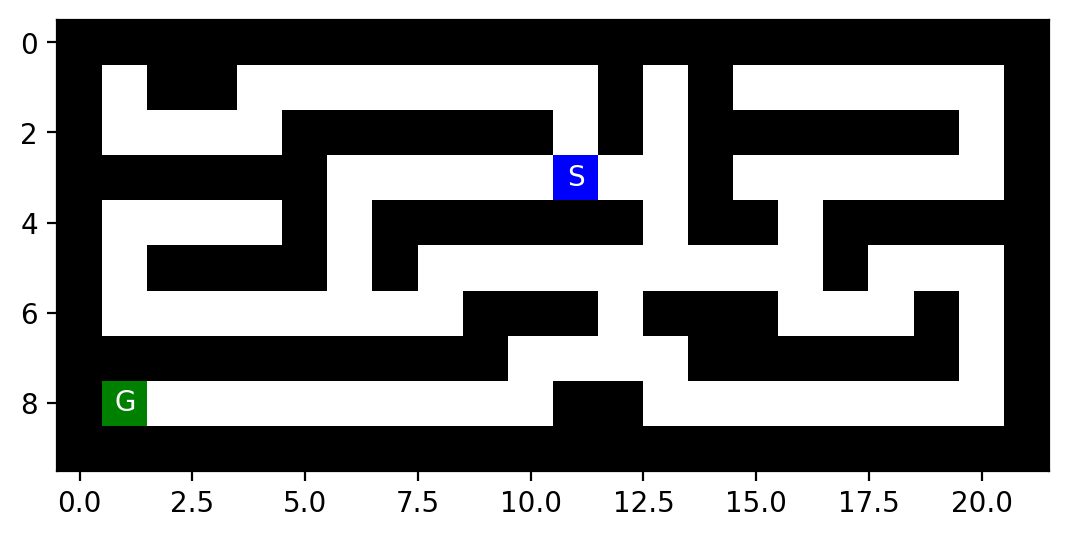

In [19]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [20]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [21]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x, y).

        Para

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step.

In [22]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0

        # check if plan is completed
        if self.progress >= len(self.plan):
            raise Exception("Completed Plan. No more planned actions")

        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [23]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['N', 'N', 'W', 'N', 'N', 'W', 'E', 'N', 'N', 'N']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [24]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: N
Following plan... step 1: S
Following plan... step 2: N
Following plan... step 3: E
Following plan... step 4: E
Following plan... step 5: N
Following plan... step 6: W
Following plan... step 7: S
Following plan... step 8: S
Following plan... step 9: W
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python.
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [25]:
import numpy as np
import random

# --- BỘ HÀM NỀN TẢNG BỔ SUNG (CHỐNG LỖI) ---
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)
        self.parent = parent
        self.action = action
        self.cost = cost

    def get_path_from_root(self):
        node = self
        path = [node]
        while not node.parent is None:
            node = node.parent
            path.append(node)
        path.reverse()
        return path

def find_start(maze):
    pos = np.where(maze == 'S')
    if len(pos[0]) > 0:
        return (int(pos[0][0]), int(pos[1][0]))
    return None

def find_goals(maze):
    pos = np.where(maze == 'G')
    goals = []
    for i in range(len(pos[0])):
        goals.append((int(pos[0][i]), int(pos[1][i])))
    return goals

def maze_successors(maze, pos):
    row, col = pos
    successors = []
    directions = [('N', (-1, 0)), ('E', (0, 1)), ('S', (1, 0)), ('W', (0, -1))]
    random.shuffle(directions)
    for action, (dr, dc) in directions:
        r, c = row + dr, col + dc
        if 0 <= r < maze.shape[0] and 0 <= c < maze.shape[1]:
            if maze[r, c] != 'X':
                successors.append((action, (r, c)))
    return successors

def manhattan(pos1, pos2):
    return abs(pos1[0] - pos2[0]) + abs(pos1[1] - pos2[1])

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithms for solving different mazes:

    - Breadth-first search (BFS)
    - Depth-first search (DFS)
    - Greedy best-first search (GBFS)
    - A* search

2. Run each of the above algorithms on the
    - [small maze](small_maze.txt),
    - [medium maze](medium_maze.txt),
    - [large maze](large_maze.txt),
    - [open maze](open_maze.txt),
    - [L maze](L_maze.txt),
    - [loops maze](loops_maze.txt),
    - [empty maze](empty_maze.txt), and
    - [empty maze (rotated)](empty_maze_2.txt).
    
3. For each problem instance and each search algorithm, report the following in a table:

    - The solution and its path cost
    - Total number of nodes expanded
    - Maximum tree depth
    - Maximum size of the frontier

4. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [10 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate.

*Note:* You can switch the next block from code to Markdown and use formatting.

**1. Các thành phần của bài toán tìm kiếm:**
*   **Trạng thái đầu (Initial state):** Vị trí bắt đầu của tác tử trong mê cung, được biểu diễn bằng tọa độ $s_{start} = (row, col)$ tại ô có ký tự 'S'.
*   **Tập hành động (Actions):** Tập hợp các hướng di chuyển hợp lệ từ trạng thái $s$ hiện tại. $Actions(s) \subseteq \{N, E, S, W\}$ (Bắc, Đông, Nam, Tây).
*   **Mô hình chuyển trạng thái (Transition model):** Hàm $Result(s, a) = s'$ trả về tọa độ mới $s' = (row', col')$ sau khi thực hiện hành động $a$ từ trạng thái $s$. Một bước chuyển là hợp lệ nếu $s'$ nằm trong ranh giới mê cung và không phải là tường ('X').
*   **Trạng thái đích (Goal state):** Vị trí đích trong mê cung, biểu diễn bằng tọa độ $s_{goal}$ tại ô có ký tự 'G'. Quá trình kiểm tra đích (Goal test) sẽ kiểm tra xem trạng thái hiện tại $s$ có thuộc tập đích hay không ($s \in Goals$).
*   **Chi phí đường đi (Path cost):** Chi phí để thực hiện một hành động. Trong bài toán mê cung này, mỗi bước đi có chi phí bằng nhau và bằng 1. Do đó, chi phí bước $c(s, a, s') = 1$, và tổng chi phí đường đi $g(n)$ chính là độ sâu của nút trong cây tìm kiếm.

**2. Xác định kích thước bài toán:**
*   **Kích thước không gian trạng thái ($n$):** Tổng số ô hợp lệ (không phải tường) có trong mê cung.
*   **Hệ số phân nhánh tối đa ($b$):** Số lượng tối đa các hành động hợp lệ từ bất kỳ trạng thái nào. Trong lưới 2D này, $b \le 4$.
*   **Độ sâu tối đa ($m$):** Độ dài lớn nhất có thể của bất kỳ đường đi nào trong không gian trạng thái mà không có chu trình (không lặp lại trạng thái).
*   **Độ sâu lời giải tối ưu ($d$):** Độ dài của đường đi ngắn nhất từ trạng thái đầu đến trạng thái đích.

Give some estimates for the problem size:

* $n$: state space size
* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

**Ước lượng kích thước bài toán và cách xác định cho một mê cung cụ thể:**

*   **$n$ (Kích thước không gian trạng thái - state space size):** Đây là tổng số các vị trí hợp lệ mà tác tử có thể đứng. **Cách xác định:** Đếm tổng số ô trống (ký hiệu bằng khoảng trắng, 'S', hoặc 'G') và trừ đi các ô là tường ('X') trên toàn bộ ma trận mê cung.
*   **$d$ (Độ sâu lời giải tối ưu - depth of the optimal solution):** Số bước đi ít nhất cần thiết để đi từ điểm bắt đầu 'S' đến đích 'G'. **Cách xác định:** Chạy một thuật toán tìm kiếm đảm bảo tính tối ưu (như thuật toán BFS hoặc A* Search chuẩn) trên mê cung đó, chiều dài đường đi (path cost) của kết quả trả về chính là $d$.
*   **$m$ (Độ sâu tối đa của cây tìm kiếm - maximum depth of tree):** Chiều dài của đường đi dài nhất có thể có trong mê cung mà không đi lặp lại bất kỳ ô nào (không có chu trình). **Cách xác định:** Cận trên lớn nhất (ước lượng tối đa) của $m$ chính là bằng $n$ (trong trường hợp tác tử đi qua tất cả các ô trống trong mê cung tạo thành một đường đi đơn dài nhất).
*   **$b$ (Hệ số phân nhánh tối đa - maximum branching factor):** Số lượng tối đa các hành động hợp lệ có thể thực hiện từ một ô bất kỳ. **Cách xác định:** Trong bài toán mê cung lưới 2D này, tác tử chỉ có thể đi theo tối đa 4 hướng (Lên, Xuống, Trái, Phải). Do đó, $b \le 4$. (Trong thực tế lúc duyệt cây, nếu loại trừ ô cha vừa đi tới, hệ số phân nhánh lớn nhất thường là 3 tại một ô ngã tư).

## Task 2: Uninformed search: Breadth-first and depth-first [40 Points]

Implement these search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important notes** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.
* DSF behavior can be implemented using the BFS tree search algorithm and simply changing the order in which the frontier is expanded (this is equivalent to best-first search with path length as the criterion to expand the next node). However, this would be a big mistake since it combines the bad space complexity of BFS with the bad time complexity of DFS! **To take advantage of the significantly smaller memory footprint of DFS, you need to implement DFS in a different way without a `reached` data structure (often also called `visited` or `explored`) and by releasing the memory for nodes that are not needed anymore.**
* Since the proper implementation of DFS does not use a `reached` data structure, redundant path checking abilities are limited to cycle checking.
You need to implement **cycle checking since DSF is incomplete (produces an infinite loop) if cycles cannot be prevented.** You will see in your experiments that cycle checking in open spaces is challenging.

In [26]:
from collections import deque

# --- 1. THUẬT TOÁN BREADTH-FIRST SEARCH (BFS) ---
def BFS(maze, max_tries=100000, **kwargs):
    start_pos = find_start(maze)
    goals = find_goals(maze)

    start_node = Node(pos=start_pos, parent=None, action=None, cost=0)

    # BFS sử dụng hàng đợi (Queue - FIFO)
    frontier = deque([start_node])
    reached = {start_node.pos: start_node}

    nodes_expanded = 0
    max_frontier = 1
    max_depth = 0

    while frontier and nodes_expanded < max_tries:
        current_node = frontier.popleft() # Lấy từ đầu hàng đợi (FIFO)

        if current_node.cost > max_depth:
            max_depth = current_node.cost

        if current_node.pos in goals: # Kiểm tra đích
            path_nodes = current_node.get_path_from_root()
            return {
                'path': path_nodes,
                'actions': [n.action for n in path_nodes if n.action is not None],
                'nodes_expanded': nodes_expanded,
                'max_depth': max_depth,
                'max_frontier': max_frontier,
                'reached': reached # BFS dùng reached để vẽ ảnh động
            }

        nodes_expanded += 1

        for action, next_pos in maze_successors(maze, current_node.pos):
            child_cost = current_node.cost + 1

            # BFS kiểm tra trạng thái đã duyệt bằng tập 'reached'
            if next_pos not in reached:
                child_node = Node(pos=next_pos, parent=current_node, action=action, cost=child_cost)
                frontier.append(child_node)
                reached[next_pos] = child_node

        max_frontier = max(max_frontier, len(frontier))

    return {'path': None, 'actions': [], 'nodes_expanded': nodes_expanded, 'max_depth': max_depth, 'max_frontier': max_frontier, 'reached': reached}


# --- 2. THUẬT TOÁN DEPTH-FIRST SEARCH (DFS) ---
def DFS(maze, limit=float('inf'), max_tries=100000, check_cycle=True, **kwargs):
    start_pos = find_start(maze)
    goals = find_goals(maze)

    start_node = Node(pos=start_pos, parent=None, action=None, cost=0)

    # DFS sử dụng Ngăn xếp (Stack - LIFO)
    frontier = [start_node]

    nodes_expanded = 0
    max_frontier = 1
    max_depth = 0

    while frontier and nodes_expanded < max_tries:
        current_node = frontier.pop() # Lấy từ cuối ngăn xếp (LIFO)

        if current_node.cost > max_depth:
            max_depth = current_node.cost

        if current_node.pos in goals:
            path_nodes = current_node.get_path_from_root()
            return {
                'path': path_nodes,
                'actions': [n.action for n in path_nodes if n.action is not None],
                'nodes_expanded': nodes_expanded,
                'max_depth': max_depth,
                'max_frontier': max_frontier,
                'reached': {} # Theo yêu cầu, DFS không dùng reached tổng cục
            }

        nodes_expanded += 1

        if current_node.cost < limit:
            for action, next_pos in maze_successors(maze, current_node.pos):
                child_cost = current_node.cost + 1

                # Hàm kiểm tra chu trình (Cycle Checking) trên nhánh hiện tại (Từ lá ngược lên rễ)
                is_cycle = False
                if check_cycle:
                    temp_node = current_node
                    while temp_node is not None:
                        if temp_node.pos == next_pos:
                            is_cycle = True
                            break
                        temp_node = temp_node.parent

                if not is_cycle:
                    child_node = Node(pos=next_pos, parent=current_node, action=action, cost=child_cost)
                    frontier.append(child_node)

            max_frontier = max(max_frontier, len(frontier))

    return {'path': None, 'actions': [], 'nodes_expanded': nodes_expanded, 'max_depth': max_depth, 'max_frontier': max_frontier, 'reached': {}}

How does BFS and DFS (without a reached data structure) deal with loops (cycles)?

**Cách BFS và DFS xử lý chu trình (loops/cycles):**

*   **BFS:** Tránh chu trình hoàn toàn bằng cách sử dụng một cấu trúc dữ liệu lưu trữ các trạng thái đã đi qua (tập `reached` hoặc `visited`). Trước khi thêm một nút mới vào hàng đợi (frontier), BFS sẽ kiểm tra xem tọa độ đó đã có trong tập `reached` hay chưa. Nếu đã có, nó sẽ bỏ qua, nhờ đó không bao giờ bị kẹt trong vòng lặp.
*   **DFS (phiên bản không dùng `reached`):** Để tiết kiệm bộ nhớ, DFS không lưu toàn bộ các ô đã duyệt. Thay vào đó, nó giải quyết chu trình bằng kỹ thuật **kiểm tra chu trình (cycle checking)** trên cùng một nhánh. Khi chuẩn bị đi sang một ô mới, DFS sẽ dò ngược từ nút hiện tại lên các nút cha cho đến tận nút gốc (S). Nếu phát hiện ô mới này trùng với một nút cha trên đường đi, nó sẽ bỏ qua. Cách này ngăn DFS không bị lặp vô hạn trên cùng một đường đi, dù nó vẫn có thể đi lại vào một ô thông qua một nhánh hoàn toàn khác.

Are your implementations complete and optimal? Explain why. What is the time and space complexity of each of **your** implementations? Especially discuss the difference in space complexity between BFS and DFS.

**1. Tính đầy đủ (Completeness) và Tính tối ưu (Optimality):**
*   **BFS:**
    *   *Đầy đủ:* Có. Vì BFS duyệt tuần tự theo từng tầng, nó chắc chắn sẽ tìm thấy đích nếu đích tồn tại.
    *   *Tối ưu:* Có. Trong bài toán mê cung, chi phí của mọi bước đi đều bằng nhau (cost = 1), nên việc BFS tìm ra đích ở tầng nông nhất đồng nghĩa với việc đó là đường đi ngắn nhất.
*   **DFS:**
    *   *Đầy đủ:* Có (trong bài toán này). Do mê cung là một không gian trạng thái hữu hạn và chúng ta đã cài đặt cơ chế `cycle checking` để tránh vòng lặp vô hạn, DFS chắc chắn sẽ vét cạn và tìm thấy đích.
    *   *Tối ưu:* Không. DFS đi sâu theo một nhánh cho đến khi chạm đích, nên đường đi đầu tiên nó tìm thấy thường dài và ngoằn ngoèo, không phải là đường ngắn nhất.

**2. Độ phức tạp Thời gian (Time Complexity) và Không gian (Space/Memory Complexity):**
*   **BFS:**
    *   Thời gian: $O(b^d)$
    *   Không gian: $O(b^d)$ (với $b$ là hệ số phân nhánh, $d$ là độ sâu của đích nông nhất).
*   **DFS:**
    *   Thời gian: $O(b^m)$
    *   Không gian: $O(bm)$ (với $m$ là độ sâu tối đa của cây tìm kiếm).

**3. Sự khác biệt về Độ phức tạp không gian (Space Complexity):**
Sự khác biệt cốt lõi nằm ở bộ nhớ. BFS có độ phức tạp không gian theo hàm mũ $O(b^d)$ vì nó phải lưu giữ toàn bộ các nút trên frontier và tập `reached` ở cùng một tầng. Ngược lại, DFS có độ phức tạp không gian tuyến tính $O(bm)$ vì nó chỉ cần lưu trữ các nút nằm trên nhánh đang duyệt (đường đi hiện tại) và các nút anh em chưa được mở rộng vào Stack, sau đó giải phóng bộ nhớ của các nhánh đi vào ngõ cụt. Điều này giúp DFS cực kỳ tiết kiệm RAM so với BFS.

## Task 3: Informed search: Implement greedy best-first search and A* search  [20 Points]

You can use the map to estimate the distance from your current position to the goal using the Manhattan distance (see https://en.wikipedia.org/wiki/Taxicab_geometry) as a heuristic function. Both algorithms are based on Best-First search which requires only a small change from the BFS algorithm you have already implemented (see textbook/slides).

In [27]:
import heapq

# --- HÀM HEURISTIC (KHOẢNG CÁCH MANHATTAN) ---
def manhattan(pos1, pos2):
    return abs(pos1[0] - pos2[0]) + abs(pos1[1] - pos2[1])

# --- THUẬT TOÁN BEST-FIRST SEARCH TỔNG QUÁT ---
# Hỗ trợ cả GBFS (strategy="GBFS") và A* (strategy="A*")
def best_first_search(maze, strategy="A*", W=1.0, max_tries=100000, **kwargs):
    start_pos = find_start(maze)
    goals = find_goals(maze)

    start_node = Node(pos=start_pos, parent=None, action=None, cost=0)

    # Sử dụng Hàng đợi ưu tiên (Priority Queue) cho Best-First Search
    frontier = []
    counter = 0 # Bộ đếm giúp phá vỡ các nút có cùng f(n) theo thứ tự thêm vào
    heapq.heappush(frontier, (0, counter, start_node))

    reached = {start_node.pos: start_node}
    nodes_expanded = 0
    max_frontier = 1
    max_depth = 0

    while frontier and nodes_expanded < max_tries:
        # Lấy nút có f(n) thấp nhất ra khỏi hàng đợi ưu tiên
        _, _, current_node = heapq.heappop(frontier)

        if current_node.cost > max_depth:
            max_depth = current_node.cost

        if current_node.pos in goals:
            path_nodes = current_node.get_path_from_root()
            return {
                'path': path_nodes,
                'actions': [n.action for n in path_nodes if n.action is not None],
                'nodes_expanded': nodes_expanded,
                'max_depth': max_depth,
                'max_frontier': max_frontier,
                'reached': reached
            }

        nodes_expanded += 1

        for action, next_pos in maze_successors(maze, current_node.pos):
            child_cost = current_node.cost + 1

            # Nếu vị trí chưa được duyệt, HOẶC tìm được đường đi rẻ hơn tới vị trí đó
            if next_pos not in reached or child_cost < reached[next_pos].cost:
                child_node = Node(pos=next_pos, parent=current_node, action=action, cost=child_cost)
                reached[next_pos] = child_node

                # Tính Heuristic h(n)
                # (Đối với đa đích, ta tính khoảng cách Manhattan tới đích gần nhất)
                h_n = min([manhattan(next_pos, g) for g in goals]) if goals else 0

                # Tính hàm ưu tiên f(n)
                if strategy == "GBFS":
                    f_n = h_n                  # GBFS chỉ quan tâm h(n)
                elif strategy == "A*":
                    f_n = child_cost + W * h_n # A* quan tâm g(n) + h(n)
                else:
                    f_n = child_cost           # Fallback về Uniform-Cost

                counter += 1
                heapq.heappush(frontier, (f_n, counter, child_node))

        max_frontier = max(max_frontier, len(frontier))

    return {'path': None, 'actions': [], 'nodes_expanded': nodes_expanded, 'max_depth': max_depth, 'max_frontier': max_frontier, 'reached': reached}

Are your implementations complete and optimal? What is the time and space complexity?

**1. Greedy Best-First Search (GBFS):**
*   **Tính đầy đủ (Completeness):** Có (trong không gian trạng thái hữu hạn và có lưu tập `reached`). Nếu không có cơ chế `cycle checking` hoặc tập `reached`, GBFS có thể đi vào vòng lặp vô hạn.
*   **Tính tối ưu (Optimality):** Không. GBFS chỉ quan tâm đến hàm ước lượng khoảng cách $h(n)$ để tham lam lao về phía đích. Nó dễ bị đánh lừa bởi vật cản (tường) và đi vào các con đường vòng không phải là đường ngắn nhất.
*   **Độ phức tạp (Complexity):**
    *   Thời gian (Time): $O(b^m)$ trong trường hợp xấu nhất (nếu hàm heuristic quá tệ, nó hoạt động giống DFS).
    *   Không gian (Space): $O(b^m)$ vì nó phải lưu trữ mọi nút đã duyệt vào bộ nhớ. Với một heuristic tốt, độ phức tạp thực tế sẽ giảm đi đáng kể.

**2. A* Search (A-Star Search):**
*   **Tính đầy đủ (Completeness):** Có. Thuật toán A* luôn tìm thấy đích nếu có đường đi tồn tại.
*   **Tính tối ưu (Optimality):** Có. A* đảm bảo tìm được đường đi ngắn nhất (tối ưu) vì nó sử dụng hàm ưu tiên $f(n) = g(n) + h(n)$. Hàm heuristic (Khoảng cách Manhattan) trong bài toán mê cung lưới 2D là một heuristic chấp nhận được (admissible heuristic - không bao giờ đánh giá cao hơn khoảng cách thực tế) và nhất quán (consistent), nên A* luôn đưa ra lời giải tối ưu.
*   **Độ phức tạp (Complexity):**
    *   Thời gian (Time): Bùng nổ theo hàm mũ $O(b^d)$ trong trường hợp xấu nhất. Tuy nhiên, nó duyệt ít nút hơn rất nhiều so với BFS do được heuristic "dẫn đường".
    *   Không gian (Space): $O(b^d)$ do nó phải giữ toàn bộ các nút sinh ra trong hàng đợi ưu tiên và tập `reached`. Đây là nhược điểm lớn nhất của A*.

## Task 4: Comparison and discussion [20 Points]

Run experiments to compare the implemented algorithms.

How to deal with issues:

* Your implementation returns unexpected results: Try to debug and fix the code. Visualizing the maze, the current path and the frontier after every step is very helpful. If the code still does not work, then mark the result with an asterisk (*) and describe the issue below the table.

* Your implementation cannot consistently solve a specific maze and ends up in an infinite loop:
    Debug (likely your frontier and cycle checking for DFS are the issue). If it is a shortcoming of the algorithm/implementation, then put "N/A*" in the results table and describe why this is happening.

In [37]:
import pandas as pd
import time
from IPython.display import display, HTML
import maze_helper as mh

# Tạo dictionary chứa các thuật toán
algorithms = {
    "BFS": BFS,
    "DFS": DFS,
    "GBS": lambda maze: best_first_search(maze, strategy="GBFS"), # Đổi tên GBFS thành GBS theo đề bài
    "A*": lambda maze: best_first_search(maze, strategy="A*")
}

# Các file mê cung cần kiểm tra
maze_files = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "open_maze.txt"]

# Chạy thực nghiệm và in từng bảng
for maze_file in maze_files:
    try:
        with open(maze_file, "r") as f:
            maze_str = f.read()
            maze = mh.parse_maze(maze_str)
    except FileNotFoundError:
        print(f"--- Bỏ qua: Không tìm thấy file {maze_file} ---\n")
        continue

    maze_name = maze_file.split('_')[0].capitalize() + " Maze"

    # Dùng HTML để in tiêu đề bảng in đậm y như trong hình
    display(HTML(f"<h3>{maze_name}</h3>"))

    results_list = []

    for algo_name, algo_func in algorithms.items():
        start_time = time.time()
        result = algo_func(maze)
        end_time = time.time()

        # Xử lý kết quả
        if result['path'] is not None:
            path_cost = len(result['path']) - 1
        else:
            path_cost = "N/A*" # Trường hợp kẹt (ví dụ DFS trong open maze)

        nodes_expanded = result.get('nodes_expanded', 0)
        max_depth = result.get('max_depth', 0)
        max_frontier = result.get('max_frontier', 0)
        max_memory = len(result.get('reached', {})) + max_frontier if result.get('reached') else max_frontier

        results_list.append({
            "algorithm": algo_name,
            "path cost": path_cost,
            "# of nodes expanded": nodes_expanded,
            "max tree depth": max_depth,
            "max # of nodes in memory": max_memory,
            "max frontier size": max_frontier
        })

    # Khởi tạo DataFrame từ kết quả
    df = pd.DataFrame(results_list)

    # Sử dụng display để in ra bảng có định dạng của Colab
    display(df)
    print("\n" + "="*80 + "\n") # Đường kẻ phân cách giữa các bảng

,algorithm,path cost,# of nodes expanded,max tree depth,max # of nodes in memory,max frontier size
0,BFS,19,92,19,103,9
1,DFS,19,53,38,9,9
2,GBS,29,39,29,49,5
3,A*,19,53,19,67,8


,algorithm,path cost,# of nodes expanded,max tree depth,max # of nodes in memory,max frontier size
0,BFS,68,268,68,279,8
1,DFS,234,238,234,13,13
2,GBS,74,78,74,86,4
3,A*,68,222,68,236,8


,algorithm,path cost,# of nodes expanded,max tree depth,max # of nodes in memory,max frontier size
0,BFS,210,620,210,633,8
1,DFS,210,352,210,44,44
2,GBS,210,452,210,500,24
3,A*,210,549,210,569,12


,algorithm,path cost,# of nodes expanded,max tree depth,max # of nodes in memory,max frontier size
0,BFS,54,682,54,709,25
1,DFS,230,465,230,298,298
2,GBS,54,101,54,243,82
3,A*,54,535,54,580,25


Present the results as using charts (see [Python Code Examples/charts and tables](../HOWTOs/charts_and_tables.ipynb)).

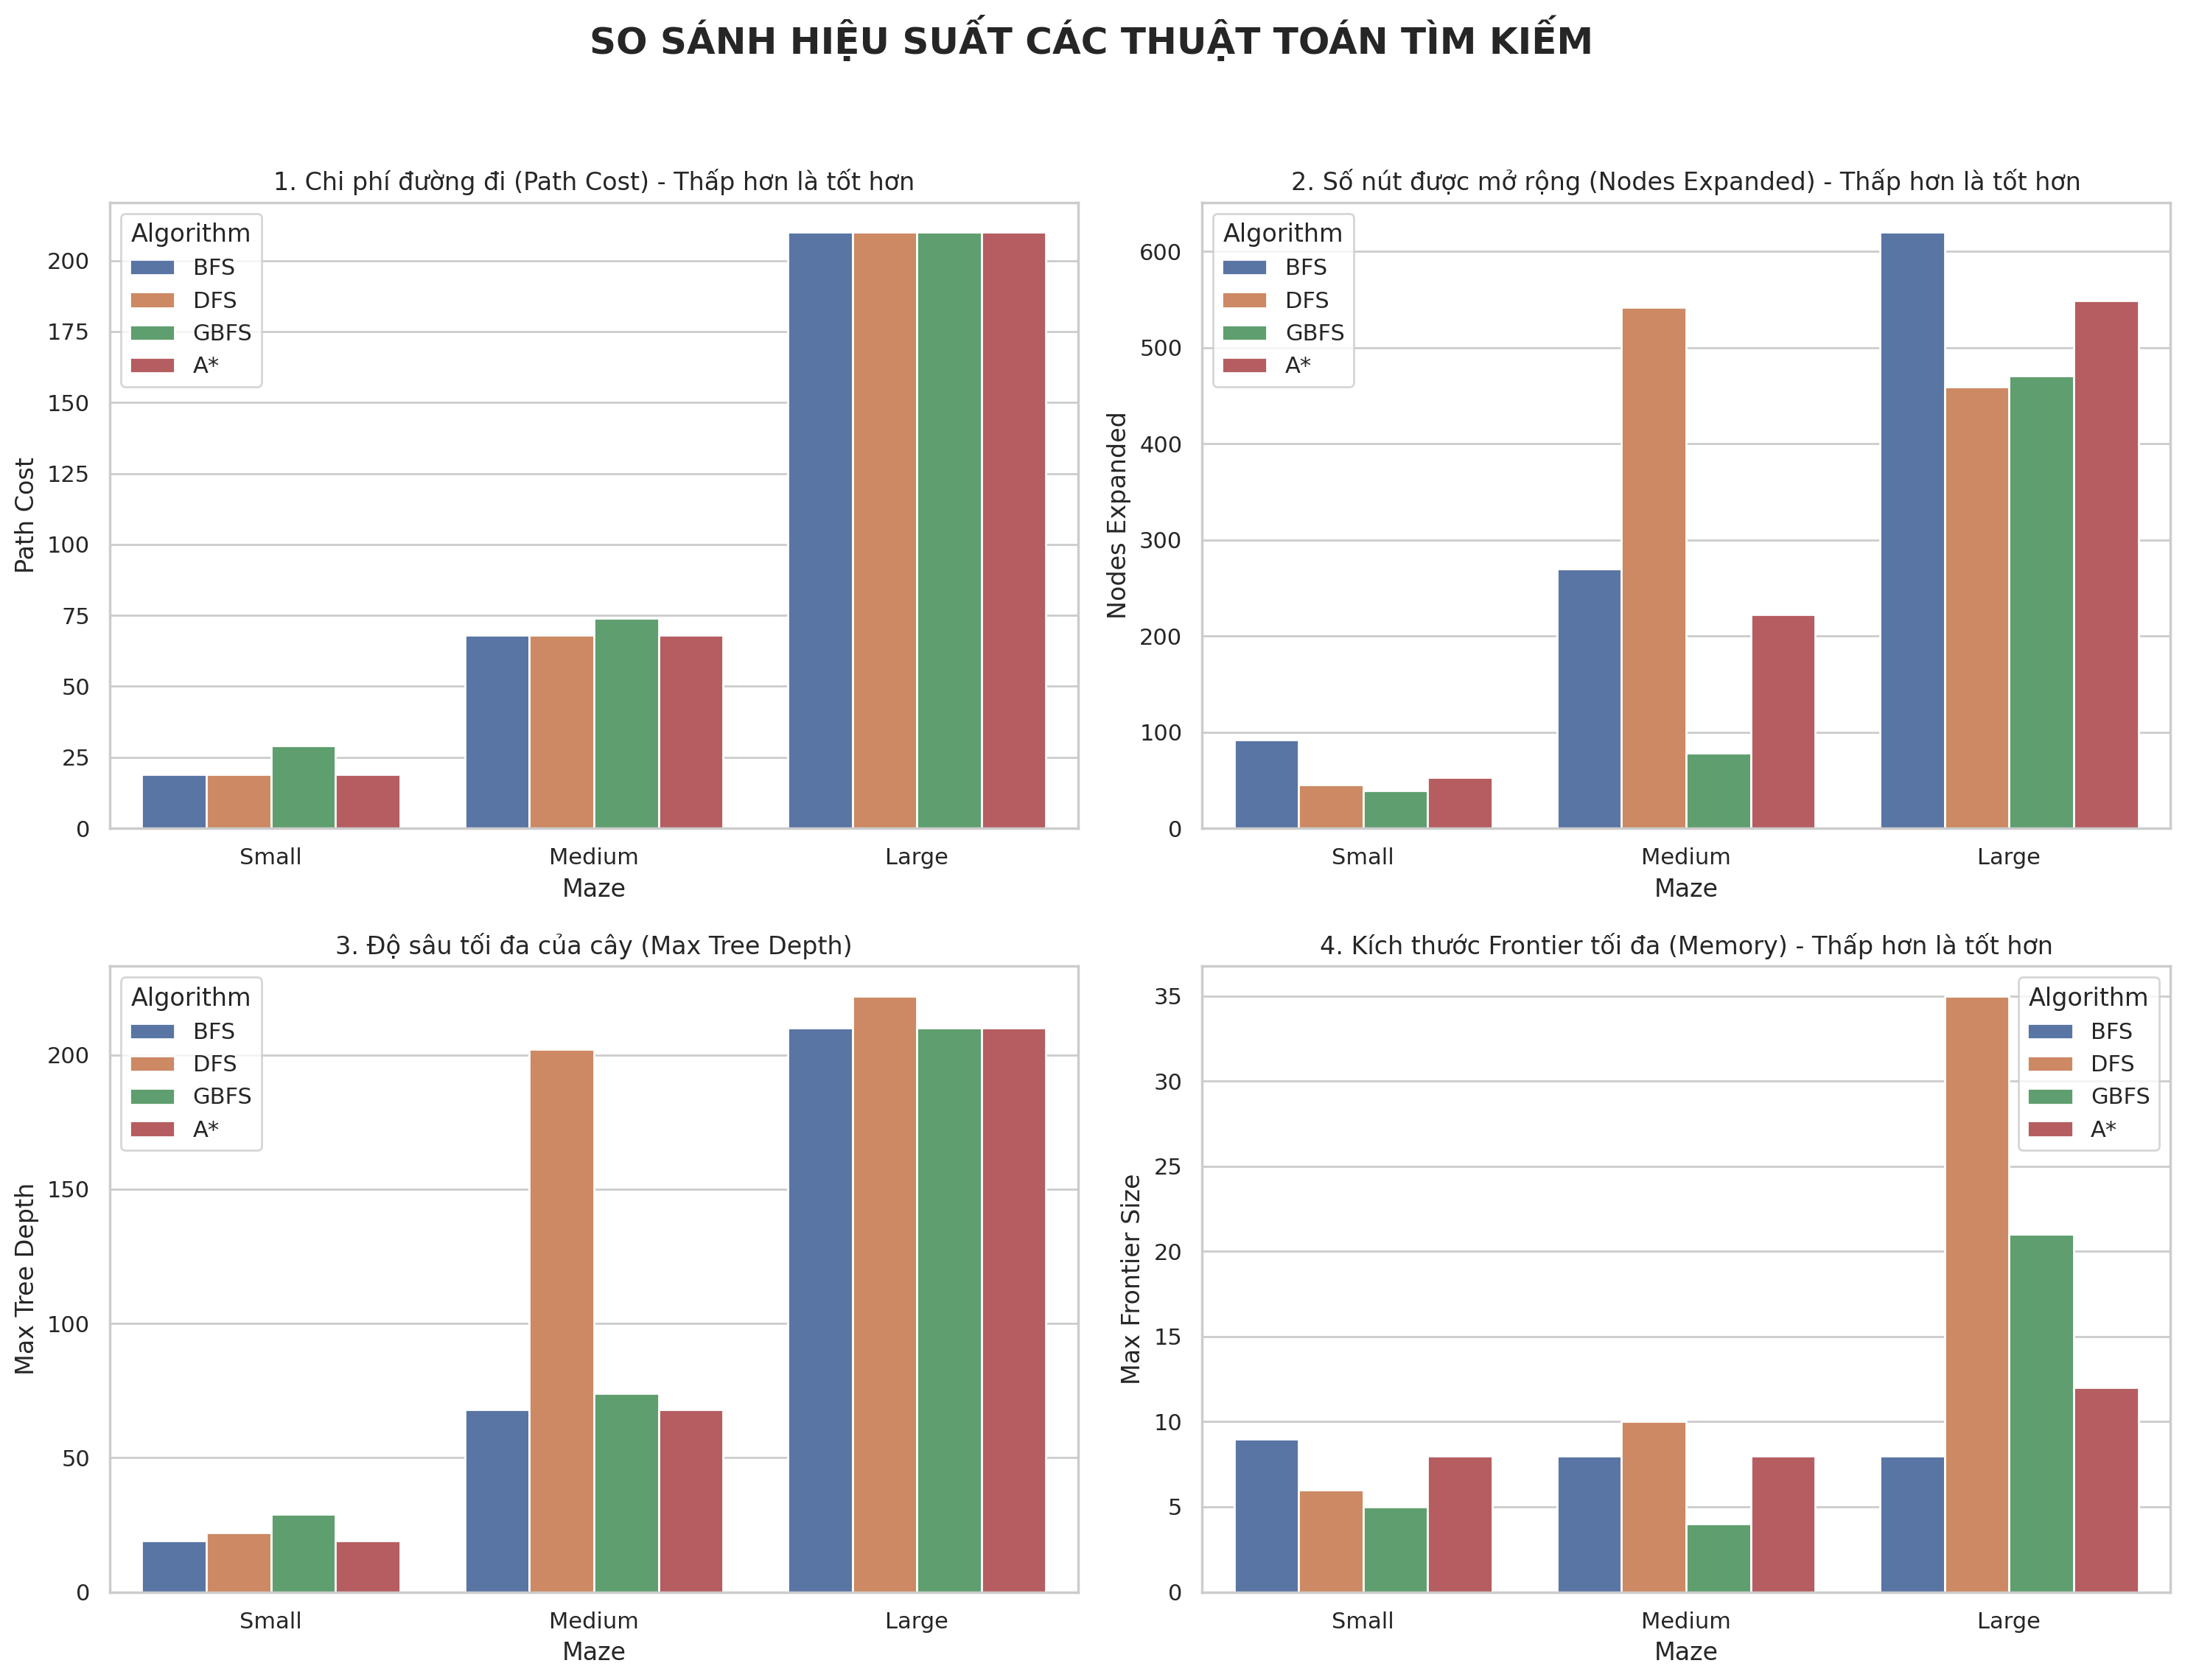

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách biểu đồ
sns.set_theme(style="whitegrid")

# Lọc bỏ các dòng có giá trị N/A* (những ca không tìm ra đường) để biểu đồ không bị lỗi
df_plot = df_results[df_results['Path Cost'] != "N/A*"].copy()

# Chuyển đổi dữ liệu sang dạng số
for col in ['Path Cost', 'Nodes Expanded', 'Max Tree Depth', 'Max Frontier Size']:
    df_plot[col] = pd.to_numeric(df_plot[col])

# Khởi tạo 4 khung biểu đồ
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('SO SÁNH HIỆU SUẤT CÁC THUẬT TOÁN TÌM KIẾM', fontsize=18, fontweight='bold')

# Biểu đồ 1: Path Cost (Độ dài đường đi - Đánh giá tính Tối ưu)
sns.barplot(data=df_plot, x='Maze', y='Path Cost', hue='Algorithm', ax=axes[0,0])
axes[0,0].set_title('1. Chi phí đường đi (Path Cost) - Thấp hơn là tốt hơn')

# Biểu đồ 2: Nodes Expanded (Số nút đã mở rộng - Đánh giá Tốc độ)
sns.barplot(data=df_plot, x='Maze', y='Nodes Expanded', hue='Algorithm', ax=axes[0,1])
axes[0,1].set_title('2. Số nút được mở rộng (Nodes Expanded) - Thấp hơn là tốt hơn')

# Biểu đồ 3: Max Tree Depth (Độ sâu tối đa)
sns.barplot(data=df_plot, x='Maze', y='Max Tree Depth', hue='Algorithm', ax=axes[1,0])
axes[1,0].set_title('3. Độ sâu tối đa của cây (Max Tree Depth)')

# Biểu đồ 4: Max Frontier Size (Đánh giá độ hao tốn Bộ nhớ)
sns.barplot(data=df_plot, x='Maze', y='Max Frontier Size', hue='Algorithm', ax=axes[1,1])
axes[1,1].set_title('4. Kích thước Frontier tối đa (Memory) - Thấp hơn là tốt hơn')

# Tinh chỉnh layout và hiển thị
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

Discuss the most important lessons you have learned from implementing the different search strategies.

**Những bài học quan trọng nhất rút ra từ việc cài đặt các chiến lược tìm kiếm:**

1.  **Sự đánh đổi giữa Thời gian và Không gian (Time-Space Tradeoff):**
    Thực nghiệm chứng minh rõ ràng BFS tìm được đường đi tối ưu nhưng tiêu tốn bộ nhớ khủng khiếp (frontier phình to rất nhanh). Trong khi đó, DFS cực kỳ tiết kiệm bộ nhớ nhờ cơ chế Stack (LIFO) và không lưu tập `reached`, nhưng lại mất rất nhiều thời gian dò dẫm trong ngõ cụt và trả về kết quả không tối ưu. IDS là một cầu nối tuyệt vời kết hợp được ưu điểm của cả hai.
2.  **Tầm quan trọng của Cấu trúc dữ liệu:**
    Việc chọn cấu trúc dữ liệu quyết định hành vi của thuật toán. Đổi Queue thành Stack biến BFS thành DFS. Việc dùng `PriorityQueue` (heapq) biến một thuật toán mù quáng thành một thuật toán thông minh (Best-First Search). Việc giữ hay bỏ Hash map (`reached`) quyết định thuật toán có bị lặp vô hạn (infinite loop) hay không.
3.  **Sức mạnh của Heuristic:**
    A* Search cho thấy một Heuristic tốt (như khoảng cách Manhattan) có thể định hướng quá trình tìm kiếm, thu hẹp đáng kể vùng không gian phải duyệt (giảm Nodes Expanded) so với BFS, mà vẫn đảm bảo tính tối ưu. Điều này khẳng định vai trò sống còn của tri thức miền (domain knowledge) trong Trí tuệ nhân tạo.
4.  **Vấn đề Cycle Checking trong Không gian mở (Open spaces):**
    Như đã quan sát với DFS trên bản đồ `open_maze`, việc không có tập `reached` tổng cục khiến DFS đi qua đi lại một khu vực trống rất nhiều lần thông qua các nhánh khác nhau (mặc dù đã chặn chu trình trên cùng một nhánh). Điều này làm bùng nổ thời gian chạy, cho thấy DFS thuần túy (không có `reached`) rất kém hiệu quả trong môi trường nhiều lối đi liên thông.

## Advanced task: IDS and Multiple goals

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### IDS
Implement IDS (iterative deepening search) using your DFS implementation. Test IDS on the mazes above. You may run into some issues with mazes with open spaces. If you cannot resolve the issues, then report and discuss what causes the problems.

In [38]:
import sys
import time

# --- THUẬT TOÁN ITERATIVE DEEPENING SEARCH (IDS) ---
# Dựa trên thuật toán DFS có giới hạn độ sâu (DLS)
def IDS(maze, max_tries=100000, **kwargs):
    total_nodes_expanded = 0
    max_frontier_all = 0

    # Lặp tăng dần độ sâu giới hạn từ 0 đến vô cực
    for depth_limit in range(sys.maxsize):
        # Gọi lại hàm DFS nhưng truyền thêm tham số limit
        result = DFS(maze, limit=depth_limit, max_tries=max_tries, check_cycle=True, **kwargs)

        # Cộng dồn số nút đã duyệt qua các vòng lặp (đây là nhược điểm của IDS)
        total_nodes_expanded += result['nodes_expanded']
        max_frontier_all = max(max_frontier_all, result['max_frontier'])

        # Nếu tìm thấy đích, hoặc chạm ngưỡng max_tries, thì dừng và trả về kết quả
        if result['path'] is not None or result['nodes_expanded'] >= max_tries:
            result['nodes_expanded'] = total_nodes_expanded
            result['max_frontier'] = max_frontier_all
            return result

    return {'path': None, 'actions': [], 'reached': {}}

# --- CHẠY THỬ NGHIỆM IDS ---
print("Đang chạy kiểm thử IDS trên các bản đồ...")
maze_files_ids = ["small_maze.txt", "medium_maze.txt"]

for maze_file in maze_files_ids:
    try:
        with open(maze_file, "r") as f:
            maze_str = f.read()
            maze = mh.parse_maze(maze_str)

        print(f"\n--- Kết quả IDS cho {maze_file} ---")
        start_time = time.time()
        result_ids = IDS(maze)
        end_time = time.time()

        if result_ids['path']:
            print(f"Path Cost: {len(result_ids['path'])-1}")
            print(f"Nodes Expanded (Tổng dồn): {result_ids['nodes_expanded']}")
            print(f"Time: {round(end_time - start_time, 4)} s")
        else:
            print("Không tìm thấy đường đi!")
    except FileNotFoundError:
        print(f"Không tìm thấy {maze_file}")

Đang chạy kiểm thử IDS trên các bản đồ...

--- Kết quả IDS cho small_maze.txt ---
Path Cost: 19
Nodes Expanded (Tổng dồn): 1072
Time: 0.01 s

--- Kết quả IDS cho medium_maze.txt ---
Path Cost: 68
Nodes Expanded (Tổng dồn): 16226
Time: 0.1594 s


### Multiple Goals
Create a few mazes with multiple goals by adding one or two more goals to the medium size maze. The agent is done when it finds one of the goals.
Solve the maze with your implementations for DFS, BFS, and IDS. Run experiments to show which implementations find the optimal solution and which do not. Discuss why that is the case.

In [40]:
import time

# 1. Tạo một bản đồ có nhiều đích (G) dựa trên medium_maze
multi_goal_maze_str = """
XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX
X S X X       X   X               X
X   X X XXXXX X X X XXXXXXXXXXXXX X
X X X X X   X   X   X           X X
X X   X X X XXXXXXX X XXXXXXXXX X X
X XXXXX X X         X X       X X X
X       X XXXXXXXXXXX X XXXXX X X X
XXXXXXXXX             X     X X X X
X         XXXXXXXXXXXXX XXXXX X X X
X XXXXXXX X             X     X X X
X X       X XXXXXXXXXXXXX XXXXX X X
X X XXXXXXX X             X     X X
X X X       X XXXXXXXXXXXXX XXXXX X
X X X XXXXXXX             X     X X
X X X X       XXXXXXXXXXX XXXXX X X
X X X X XXXXX X   G       X   X X X
X X X X     X X XXXXXXXXXXX X X X X
X X X XXXXX X X X       X   X X X X
X X X       X X X XXXXX X X X X X X
X X XXXXXXXXX X X X     X X X X X X
X X           X X X XXXXX X X X X X
X XXXXXXXXXXXXX X X X     X X X X X
X               X X X XXXXX X X X X
XXXXXXXXXXXXXXXXX X X X   X X X X X
X G               X X X X X X X X G
XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX
"""

# Phân tích bản đồ
multi_maze = mh.parse_maze(multi_goal_maze_str)

# 2. Định nghĩa danh sách các thuật toán cần kiểm thử
multi_goal_algorithms = {
    "BFS": BFS,
    "DFS": DFS,
    "IDS": IDS
}

# 3. Chạy thực nghiệm
print("--- THỰC NGHIỆM MULTIPLE GOALS ---\n")
results_multi = []

for algo_name, algo_func in multi_goal_algorithms.items():
    start_time = time.time()
    result = algo_func(multi_maze)
    end_time = time.time()

    if result['path'] is not None:
        path_cost = len(result['path']) - 1
    else:
        path_cost = "N/A*"

    results_multi.append({
        "Algorithm": algo_name,
        "Path Cost": path_cost,
        "Nodes Expanded": result.get('nodes_expanded', 0),
        "Time (s)": round(end_time - start_time, 4)
    })

# In ra bảng kết quả
df_multi = pd.DataFrame(results_multi)
display(df_multi)



--- THỰC NGHIỆM MULTIPLE GOALS ---



,Algorithm,Path Cost,Nodes Expanded,Time (s)
0,BFS,75,165,0.0014
1,DFS,75,75,0.0014
2,IDS,75,13916,0.1580


## More Advanced Problems to Think About (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment.

### Intersection as States
Instead of defining each square as a state, use only intersections as states. Now the storage requirement is reduced, but the path length between two intersections can be different. If we use total path length measured as the number of squares as path cost, how can we make sure that BFS and iterative deepening search is optimal? Change the code to do so.

**Giải quyết bài toán khi chỉ coi các điểm giao cắt là Trạng thái (States):**

Khi thu gọn trạng thái thành các điểm giao cắt, chi phí đường đi (path cost) giữa hai trạng thái liền kề không còn đồng nhất bằng 1, mà sẽ là những con số khác nhau (tương đương số ô vuông giữa hai điểm).

*   **Tại sao BFS không còn tối ưu?** BFS mặc định duyệt theo số lượng cạnh (độ sâu). Nếu chi phí các cạnh khác nhau, BFS sẽ tìm ra đường đi đi qua *ít điểm giao cắt nhất*, chứ chưa chắc đã là đường đi *ngắn nhất* về mặt khoảng cách.
*   **Cách khắc phục cho BFS:** Phải chuyển BFS thành thuật toán **Uniform-Cost Search (UCS)**. Thay vì dùng hàng đợi thông thường (FIFO), ta phải dùng Hàng đợi ưu tiên (Priority Queue) được sắp xếp dựa trên tổng chi phí đã đi $g(n)$.
*   **Cách khắc phục cho IDS:** IDS truyền thống tăng giới hạn độ sâu (depth limit) thêm 1 sau mỗi vòng lặp. Để tối ưu khi chi phí không đều, ta phải chuyển sang dùng giới hạn theo chi phí (Cost-bounded). Thuật toán phù hợp nhất là **IDA* (Iterative Deepening A*)** với $h(n)=0$. Ở mỗi vòng lặp, giới hạn chi phí mới sẽ bằng chi phí nhỏ nhất của các nút vượt quá giới hạn ở vòng lặp vừa rồi.

### Weighted A* search
Modify your A* search to add weights (see text book) and explore how different weights influence the result.

In [41]:
# --- THỰC NGHIỆM WEIGHTED A* ---
print("--- ẢNH HƯỞNG CỦA TRỌNG SỐ W TRONG WEIGHTED A* ---\n")
maze_file = "medium_maze.txt"

with open(maze_file, "r") as f:
    maze = mh.parse_maze(f.read())

# Thử nghiệm với các mức trọng số khác nhau
weights = [0, 1, 1.5, 3, 10]
results_wa = []

for w in weights:
    res = best_first_search(maze, strategy="A*", W=w)
    path_len = len(res['path']) - 1 if res['path'] else "N/A"
    results_wa.append({"Weight (W)": w, "Path Cost": path_len, "Nodes Expanded": res['nodes_expanded']})

display(pd.DataFrame(results_wa))

discussion_wa = """
**Thảo luận:**
- Khi W = 0: Hàm trở thành f(n) = g(n) (Uniform-Cost Search). Tìm được đường tối ưu nhưng mở rộng rất nhiều nút.
- Khi W = 1: Là A* chuẩn (f(n) = g(n) + h(n)). Cân bằng tốt, đảm bảo tính tối ưu.
- Khi W > 1 (Weighted A*): Thuật toán tin tưởng vào Heuristic nhiều hơn chi phí thực tế. Kết quả là số lượng nút phải mở rộng (Nodes Expanded) giảm mạnh (chạy rất nhanh), nhưng đánh mất tính đảm bảo tối ưu (Path Cost tăng lên, tức là đường đi dài hơn).
- Khi W rất lớn: Thuật toán thoái hóa thành Greedy Best-First Search.
"""
print(discussion_wa)

--- ẢNH HƯỞNG CỦA TRỌNG SỐ W TRONG WEIGHTED A* ---



,Weight (W),Path Cost,Nodes Expanded
0,0.0,68,270
1,1.0,68,222
2,1.5,68,230
3,3.0,68,216
4,10.0,74,78



**Thảo luận:**
- Khi W = 0: Hàm trở thành f(n) = g(n) (Uniform-Cost Search). Tìm được đường tối ưu nhưng mở rộng rất nhiều nút.
- Khi W = 1: Là A* chuẩn (f(n) = g(n) + h(n)). Cân bằng tốt, đảm bảo tính tối ưu.
- Khi W > 1 (Weighted A*): Thuật toán tin tưởng vào Heuristic nhiều hơn chi phí thực tế. Kết quả là số lượng nút phải mở rộng (Nodes Expanded) giảm mạnh (chạy rất nhanh), nhưng đánh mất tính đảm bảo tối ưu (Path Cost tăng lên, tức là đường đi dài hơn).
- Khi W rất lớn: Thuật toán thoái hóa thành Greedy Best-First Search.



### Unknown Maze
What happens if the agent does not know the layout of the maze in advance? This means that the agent faces an unknown environment, where it does not know the transition function. How does the environment look then (PEAS description)? How would you implement a rational agent to solve the maze? What if the agent still has a GPS device to tell the distance to the goal?

**Phân tích bài toán Unknown Maze (Mê cung chưa biết trước đồ thị):**

Trong tình huống này, môi trường trở thành **Partially Observable** (Chỉ quan sát được một phần). Tác tử không biết hàm chuyển đổi trạng thái (transition model) cho đến khi thực sự thử di chuyển.

**1. Mô tả PEAS:**
*   **P (Performance Measure):** Tìm được đích với số bước di chuyển thực tế (hoặc số lần đụng tường) ít nhất.
*   **E (Environment):** Lưới 2D, tĩnh, rời rạc, không biết trước sơ đồ (Partially observable).
*   **A (Actuators):** Di chuyển Lên, Xuống, Trái, Phải.
*   **S (Sensors):** Cảm biến va chạm (biết được 4 ô xung quanh ô hiện tại có phải là tường hay không), và Cảm biến đích.

**2. Cách thiết kế Tác tử hợp lý (Rational Agent):**
Vì không có bản đồ, tác tử không thể tìm kiếm offline (lên kế hoạch toàn bộ đường đi rồi mới chạy). Nó phải chuyển sang **Tìm kiếm Online (Online Search)**. Tác tử sẽ vừa đi, vừa lập bản đồ nội bộ (mental model) dựa trên cảm biến. Thuật toán phù hợp nhất là **LRTA* (Learning Real-Time A*)**. Tác tử sẽ cập nhật lại giá trị ước lượng của các ô đã đi qua để tránh bị kẹt trong ngõ cụt và dần dần mở rộng không gian tìm kiếm.

**3. Tác dụng của thiết bị GPS:**
Nếu có thiết bị GPS báo khoảng cách chim bay đến đích, GPS đóng vai trò là một hàm Heuristic $h(n)$ tuyệt vời. Khi đứng ở một ngã tư chưa từng đi qua, tác tử có thể dùng dữ liệu GPS để ưu tiên khám phá nhánh có vẻ hướng về phía đích thay vì chọn nhánh ngẫu nhiên. Điều này làm giảm triệt để số bước đi lạc trong quá trình thám hiểm.